Mount drive

In [29]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Imports

In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import seaborn as sns

Paths

In [31]:
BASE_PATH = Path("/content/drive/MyDrive/fyp")

DATASET_PATH = BASE_PATH / "Processed Dataset"

IMAGE_DIR = DATASET_PATH / "images"

MASK_DIR = DATASET_PATH / "masks"

METADATA_PATH = DATASET_PATH / "metadata.csv"


print(IMAGE_DIR)
print(MASK_DIR)
print(METADATA_PATH)

/content/drive/MyDrive/fyp/Processed Dataset/images
/content/drive/MyDrive/fyp/Processed Dataset/masks
/content/drive/MyDrive/fyp/Processed Dataset/metadata.csv


### High-Speed Local Storage Setup
Reading thousands of small files (images and masks) directly from Google Drive is extremely slow because of network latency.

We can copy the processed dataset to the local Colab disk (`/content/dataset/`) to achieve maximum I/O performance. We also define a simple sync function to save any updates (like modified metadata or reports) back to Google Drive.

In [32]:
import shutil
import os

# Define local fast paths
LOCAL_BASE_PATH = Path("/content/dataset")
LOCAL_IMAGE_DIR = LOCAL_BASE_PATH / "images"
LOCAL_MASK_DIR = LOCAL_BASE_PATH / "masks"
LOCAL_METADATA_PATH = LOCAL_BASE_PATH / "metadata.csv"

# Copy the dataset from Drive to Local (only if it doesn't exist yet to save time)
if not LOCAL_BASE_PATH.exists():
    print("Copying dataset to local storage for high-speed computation...")
    shutil.copytree(DATASET_PATH, LOCAL_BASE_PATH)
    print("Done! Dataset is now available locally at /content/dataset")
else:
    print("Dataset already exists in local storage.")

Copying dataset to local storage for high-speed computation...
Done! Dataset is now available locally at /content/dataset


Load Metadata

In [33]:
df = pd.read_csv(
    LOCAL_METADATA_PATH
)

df.head()

,image,mask,class,label,patient_id,source,client_id
0,cheng_000000.png,cheng_000000_mask.png,meningioma,1,100360,cheng,NaN
1,cheng_000001.png,cheng_000001_mask.png,meningioma,1,101016,cheng,NaN
2,cheng_000002.png,cheng_000002_mask.png,meningioma,1,107494,cheng,NaN
3,cheng_000003.png,cheng_000003_mask.png,pituitary,3,112649,cheng,NaN
4,cheng_000004.png,cheng_000004_mask.png,pituitary,3,112649,cheng,NaN


Dataset Overview

In [34]:
print("Total Images:", len(df))

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

#Client_id missing -Assign during Fed Simulation
#Patient_id missing -No Tumor class only has images

Total Images: 4478

Columns:
['image', 'mask', 'class', 'label', 'patient_id', 'source', 'client_id']

Missing Values:
image            0
mask             0
class            0
label            0
patient_id    1414
source           0
client_id     4478
dtype: int64


In [35]:
class_counts = df["class"].value_counts()

class_counts
#Majority of the class is glioma
#meningioma has very less samples

,count
class,
glioma,1426
no_tumor,1414
pituitary,930
meningioma,708


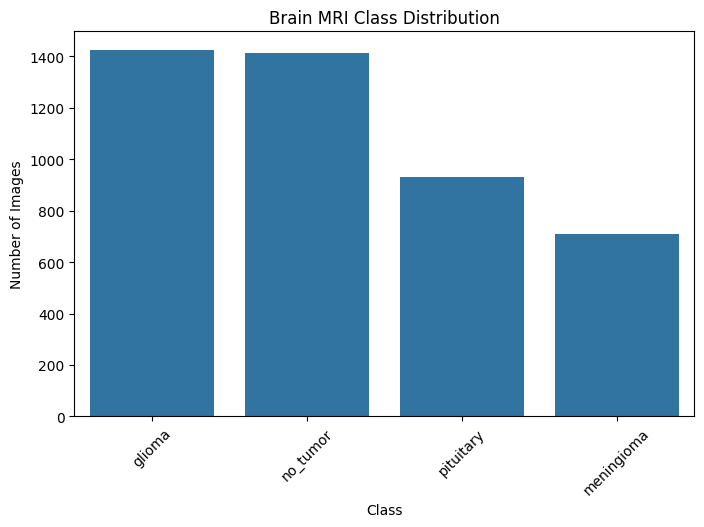

In [36]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title(
    "Brain MRI Class Distribution"
)

plt.xlabel(
    "Class"
)

plt.ylabel(
    "Number of Images"
)

plt.xticks(rotation=45)

plt.show()

Source Distributions

In [37]:
source_counts = df["source"].value_counts()

source_counts

,count
source,
cheng,3064
kaggle,1414


Image Dimension Analysis

In [38]:
widths = []
heights = []


for img_name in df["image"]:

    img = Image.open(
        LOCAL_IMAGE_DIR / img_name
    )

    w,h = img.size

    widths.append(w)
    heights.append(h)


df["width"] = widths
df["height"] = heights

Image Stats

In [39]:
df[
    ["width","height"]
].describe()

,width,height
count,4478.000000,4478.000000
mean,448.504020,452.814873
std,130.768196,124.504679
min,150.000000,168.000000
25%,428.000000,442.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,1375.000000,1446.000000


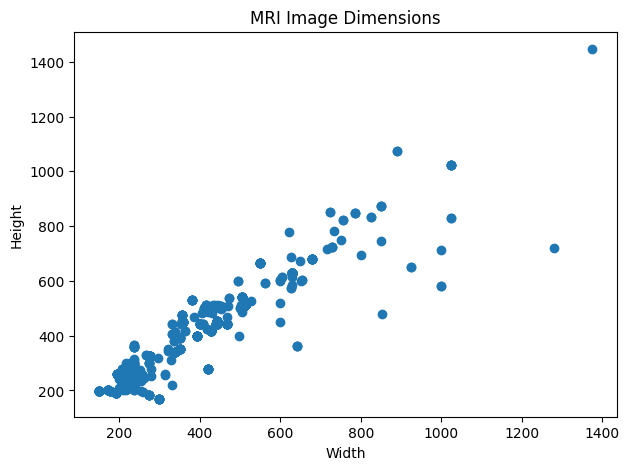

In [40]:
plt.figure(figsize=(7,5))

plt.scatter(
    df["width"],
    df["height"]
)

plt.xlabel("Width")
plt.ylabel("Height")

plt.title(
    "MRI Image Dimensions"
)

plt.show()

Analyzing pixel values

In [42]:
pixel_values=[]


sample_images = df.sample(
    min(100,len(df)),
    random_state=42
)


for img_name in sample_images["image"]:

    img = Image.open(
        LOCAL_IMAGE_DIR / img_name
    )

    img_array=np.array(img)

    pixel_values.extend(
        img_array.flatten()
    )

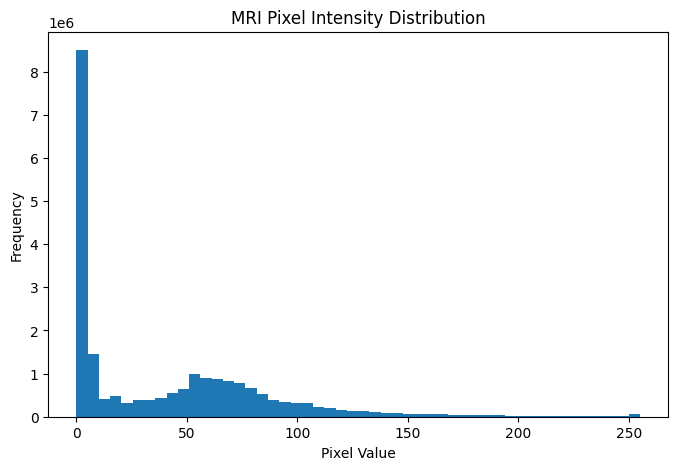

In [43]:
plt.figure(figsize=(8,5))

plt.hist(
    pixel_values,
    bins=50
)

plt.title(
    "MRI Pixel Intensity Distribution"
)

plt.xlabel(
    "Pixel Value"
)

plt.ylabel(
    "Frequency"
)

plt.show()

Display MRI samples

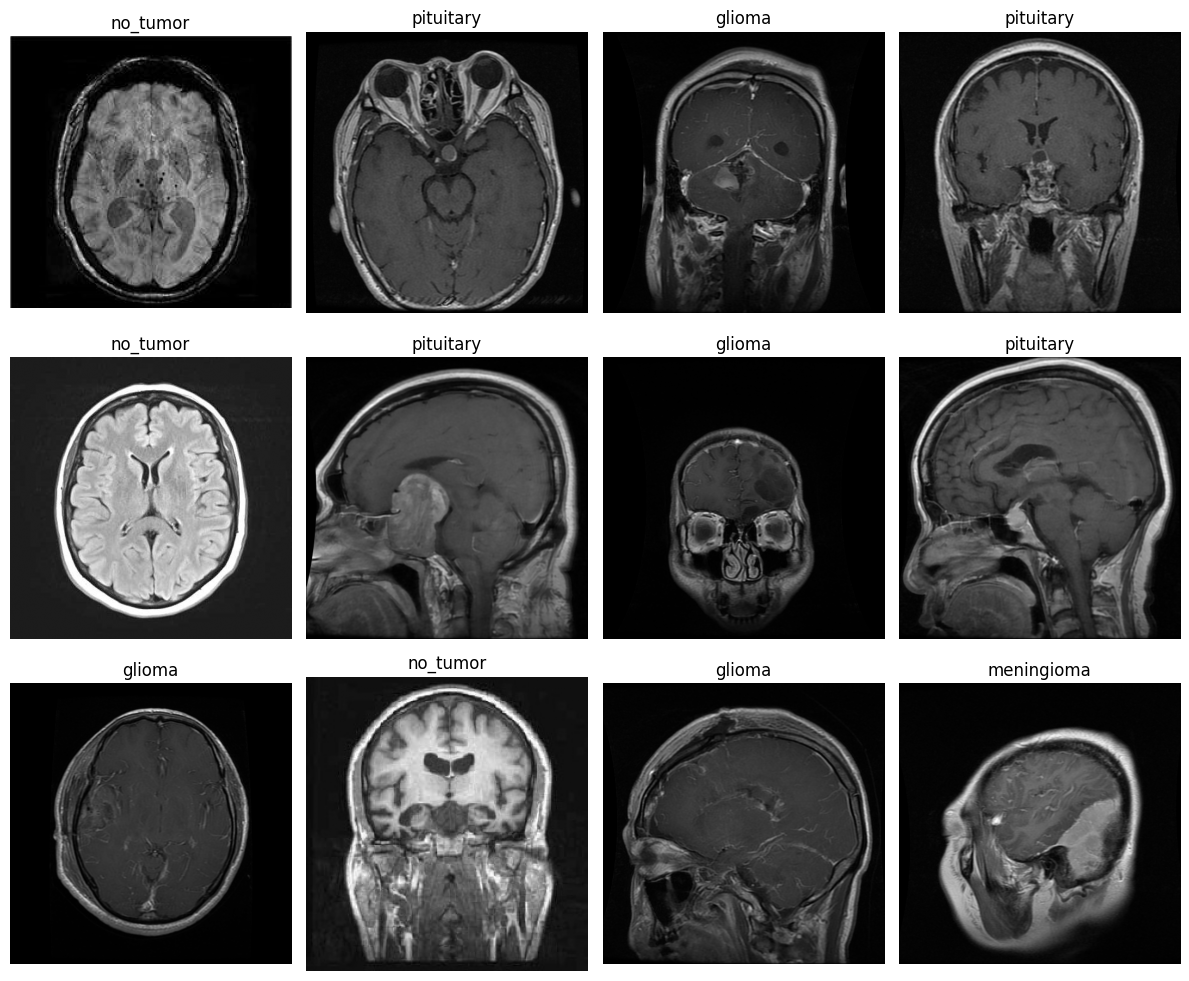

In [44]:
sample = df.sample(
    12,
    random_state=42
)


plt.figure(figsize=(12,10))


for i,(_,row) in enumerate(sample.iterrows()):

    img = Image.open(
        IMAGE_DIR / row["image"]
    )


    plt.subplot(3,4,i+1)

    plt.imshow(
        img,
        cmap="gray"
    )

    plt.title(
        row["class"]
    )

    plt.axis("off")


plt.tight_layout()

plt.show()

Display Image with its tumor mask

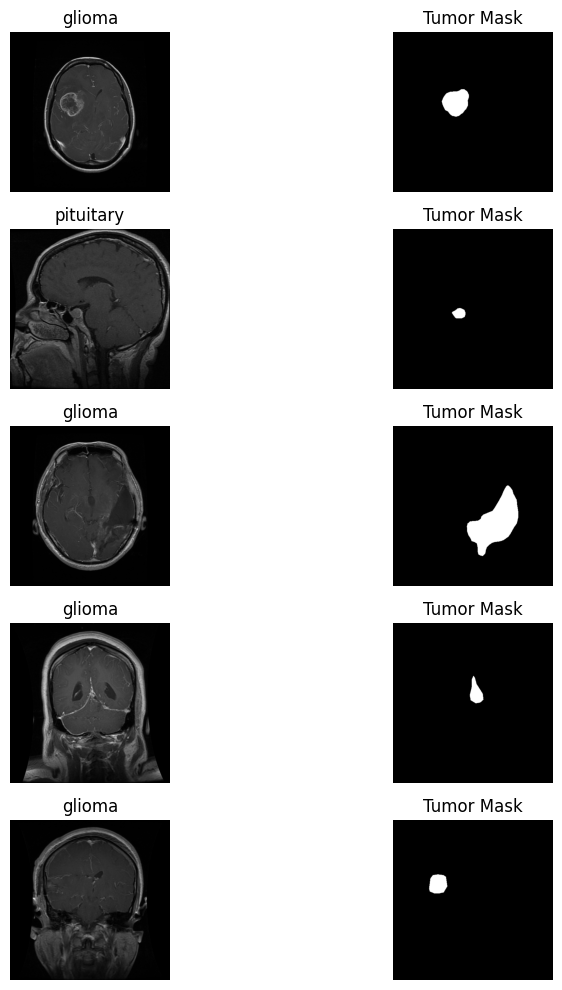

In [45]:
sample = df[
    df["source"]=="cheng"
].sample(
    5,
    random_state=42
)


plt.figure(figsize=(10,10))


for i,(_,row) in enumerate(sample.iterrows()):

    img = Image.open(
        IMAGE_DIR / row["image"]
    )

    mask = Image.open(
        MASK_DIR / row["mask"]
    )


    plt.subplot(5,2,2*i+1)

    plt.imshow(
        img,
        cmap="gray"
    )

    plt.title(
        row["class"]
    )

    plt.axis("off")


    plt.subplot(5,2,2*i+2)

    plt.imshow(
        mask,
        cmap="gray"
    )

    plt.title(
        "Tumor Mask"
    )

    plt.axis("off")


plt.tight_layout()

plt.show()

Unique Patients

In [46]:
patient_count = (
    df["patient_id"]
    .nunique()
)


print(
    "Unique Patients:",
    patient_count
)

Unique Patients: 233


In [47]:
eda_summary = {

    "total_images":len(df),

    "classes":
        df["class"]
        .value_counts()
        .to_dict(),

    "sources":
        df["source"]
        .value_counts()
        .to_dict(),

    "average_width":
        df["width"].mean(),

    "average_height":
        df["height"].mean()

}


import json


with open(
    BASE_PATH/"eda_report.json",
    "w"
) as f:

    json.dump(
        eda_summary,
        f,
        indent=4
    )


print("EDA Report Saved")

EDA Report Saved
